# Diversified futures trend following

## 1. Data, universe, and benchmark

Use one **staggered universe** of 15 futures across six groups. Select distinct exposures before looking at performance. Sovereign bonds span US short and intermediate maturities and German Bunds; FX includes EUR, JPY and GBP against USD; agriculture adds livestock alongside oilseeds and coffee. ES and MES are not separate bets. Related exposures still share risk.

Use the pinned provider's Panama-adjusted closes for signals and point P&L. Keep the paired unadjusted series for roll diagnostics, not for strategy returns. No Yahoo futures splice, spot or yield substitutions, or assumed front-month rolls. CL is the provider's winter chain. The listed multipliers match the [provider's quote units](https://github.com/pst-group/pysystemtrade/blob/bbf5cf823e16be1cca27493a94099eb8cf33f6e7/data/futures/csvconfig/instrumentconfig.csv); for example, copper is quoted in dollars per pound, while soybeans and live cattle use cents.

**Benchmark:** 100% MSCI World USD Net Total Return. Use URTH adjusted prices only as a separate investable comparison on overlapping dates. Keep EUR/USD spot as a conversion input, not a tradable future. Convert the EUR point P&L of FESX and FGBL using USD per EUR. The three currency futures already settle in USD.

**Eligibility:** inspect data from 1999 onward for warm-up. Remove weekend-labelled observations from the research panel, retaining the raw downloads. Require 252 observations plus the longest tested signal lookback (currently 100 sessions) before an instrument is eligible. Gaps over seven calendar days break the signal and risk history and restart warm-up; do not count the cross-gap change as a one-session risk observation. Existing positions remain open until the next mark. This is a conservative gap rule, not exchange-calendar reconciliation.

The audit checks provenance, file integrity, quote pairing, sample length, and FX coverage. It reports gaps, repeated closes and unusually large point moves without automatically deleting them. A large move that coincides with a change in the Panama offset needs roll review: for example, on 2003-02-25 NG rolled from April to June 2003; June fell from 6.367 to 5.539, matching the adjusted move of −0.828. The verified chains end on 2024-03-28, so later equity data do not extend the comparison. These are provider daily marks, not independently verified exchange settlements.

**Return convention for the later backtest:** a 20-point ES move on one long contract at $50 per point earns $1,000, or +1% on $100,000 of starting NAV. A Panama level shift leaves that P&L unchanged. Benchmark returns instead use percentage changes of the index or adjusted ETF level. No portfolio returns are computed in this section.

In [1]:
import hashlib  # Compute file checksums to verify downloaded inputs.
import json  # Read the structured download manifest.
from pathlib import Path  # Build portable paths to local data files.


import numpy as np  # Check numeric arrays and finite values.
import pandas as pd  # Load, align, and audit daily time series.

DATA = Path('data/trend_following_futures')  # Locate the research CSVs and source manifest.
WARMUP_START = '1999-01-01'  # Limit the candidate sample to the common research era.
BASE_HISTORY_SESSIONS = 252
MIN_HISTORY = BASE_HISTORY_SESSIONS + 100  # Require one trading year plus baseline signal warm-up.
MAX_GAP_DAYS = 7  # Treat longer calendar gaps as breaks in the observed price history.
PST_REVISION = 'bbf5cf823e16be1cca27493a94099eb8cf33f6e7'  # Pin the futures source version.

contracts = pd.DataFrame([  # Declare the chosen markets and contract-level point values.
    ('ES', 'Equity', 'S&P 500', 'SP500', 'index points', 'USD', 50),  # E-mini S&P 500, $50 per index point.
    ('FESX', 'Equity', 'Euro Stoxx 50', 'EUROSTX', 'index points', 'EUR', 10),  # Euro equity index, €10 per point.
    ('ZT', 'Sovereign bonds', 'US 2-year Treasury note', 'US2', '% of par', 'USD', 2000),  # US 2-year provider point size.
    ('ZN', 'Sovereign bonds', 'US 10-year Treasury note', 'US10', '% of par', 'USD', 1000),  # US 10-year provider point size.
    ('FGBL', 'Sovereign bonds', 'German Bund', 'BUND', '% of par', 'EUR', 1000),  # Bund point value is denominated in euros.
    ('6E', 'FX', 'Euro', 'EUR', 'USD per EUR', 'USD', 125000),  # Euro futures P&L is already in USD.
    ('6J', 'FX', 'Japanese yen', 'JPY', 'USD per JPY', 'USD', 12500000),  # Yen futures point size from provider config.
    ('6B', 'FX', 'British pound', 'GBP', 'USD per GBP', 'USD', 62500),  # Pound futures P&L is already in USD.
    ('CL', 'Energy', 'WTI crude oil (winter chain)', 'CRUDE_W', 'USD/barrel', 'USD', 1000),  # Provider uses the winter WTI chain.
    ('NG', 'Energy', 'Henry Hub natural gas', 'GAS_US', 'USD/MMBtu', 'USD', 10000),  # Natural gas point value in USD.
    ('GC', 'Metals', 'Gold', 'GOLD', 'USD/troy oz', 'USD', 100),  # Gold contract point size in troy ounces.
    ('HG', 'Metals', 'Copper', 'COPPER', 'USD/lb', 'USD', 25000),  # Match provider quote units, not an exchange shorthand.
    ('ZS', 'Agriculture', 'Soybeans', 'SOYBEAN', 'US cents/bushel', 'USD', 50),  # Provider point value for soybean quotes.
    ('KC', 'Agriculture', 'Coffee C', 'COFFEE', 'US cents/lb', 'USD', 375),  # Coffee point value in USD.
    ('LE', 'Agriculture', 'Live cattle', 'LIVECOW', 'US cents/lb', 'USD', 400),  # Live cattle point value in USD.
], columns=['market', 'sector', 'description', 'provider_id', 'quote_unit', 'currency', 'point_value']).set_index('market')  # Index rows by ticker for the audit loop.

manifest = json.loads((DATA / 'sources_manifest.json').read_text())  # Load provenance and file metadata.
records = {record['key']: record for record in manifest['series']}  # Enable direct lookup by series key.

def load_level(key, kind, currency, provider_id=None):  # Load one series only after validating its metadata.
    if key not in records:  # Fail clearly instead of silently skipping a missing required input.
        raise ValueError(f'{key}: missing; run helpers.download_trend_following_data')  # Point to the acquisition step.
    record = records[key]  # Retrieve the source record associated with this file.
    if record['series_type'] != kind or record['currency'] != currency:  # Prevent mixing different price semantics or currencies.
        raise ValueError(f'{key}: unexpected series type or currency')  # Stop when the series metadata disagrees.
    if provider_id and (record['provider'] != 'pysystemtrade' or  # Apply these source checks only to futures series.
                        record['identifier'] != provider_id or  # Confirm the provider's instrument mapping.
                        f'/{PST_REVISION}/' not in record['source_url']):  # Require the pinned source revision.
        raise ValueError(f'{key}: unexpected futures source')  # Reject unapproved futures provenance.
    path = DATA / record['file']  # Resolve the manifest's CSV filename under the data directory.
    if hashlib.sha256(path.read_bytes()).hexdigest() != record['sha256']:  # Detect file changes or corruption.
        raise ValueError(f'{key}: source checksum mismatch')  # Do not use a file that fails its integrity check.
    frame = pd.read_csv(path)  # Read daily observations from the verified CSV.
    if list(frame.columns) != ['date', 'adjusted_price'] or len(frame) != record['rows']:  # Check schema and recorded row count.
        raise ValueError(f'{key}: unexpected file structure')  # Refuse an unexpected or truncated file.
    dates = pd.DatetimeIndex(pd.to_datetime(frame['date'], format='%Y-%m-%d'))  # Parse dates into a time index.
    values = pd.to_numeric(frame['adjusted_price'], errors='raise').to_numpy()  # Parse numeric levels without coercing errors.
    if dates.hasnans or not dates.is_unique or not dates.is_monotonic_increasing or not np.isfinite(values).all():  # Check usable dates and finite values.
        raise ValueError(f'{key}: missing, repeated, unordered or nonfinite data')  # Reject malformed observations.
    return pd.Series(values, index=dates, name=key)  # Return levels with their dates and series key attached.

benchmark = load_level('MSCI_WORLD_NETR__MSCI', 'net_total_return_index', 'USD')  # Use official MSCI USD net total-return levels.
urth = load_level('URTH_PROXY__YAHOO', 'etf_adjusted_price', 'USD')  # Keep the ETF proxy as a separate comparison.
eurusd = load_level('EURUSD_SPOT__FRED_DEXUSEU', 'spot_fx', 'USD')  # Load USD-per-EUR rates for euro-denominated futures.
if any(level.le(0).any() for level in (benchmark, urth, eurusd)):  # Index and spot-FX levels must be positive.
    raise ValueError('Benchmark and FX levels must be positive')  # Prevent invalid percentage or FX calculations later.

futures = {}  # Keep each cleaned candidate panel for subsequent strategy work.
audit_rows = []  # Collect one summary record per instrument.
gap_rows = []  # Collect long gaps for manual review.
roll_review_rows = []  # Collect large moves that coincide with a roll adjustment change.
for market, spec in contracts.iterrows():  # Audit each selected instrument against its contract specification.
    
    # adjusted specifically means the provider’s Panama back-adjusted futures series
    
    adjusted = load_level(f'{market}__PST_PANAMA_BACK_ADJUSTED',  # Load the adjusted series used for signals and point moves.
                          'panama_back_adjusted', spec.currency, spec.provider_id)  # Require matching source and currency.
    active = load_level(f'{market}__PST_UNADJUSTED_ACTIVE_CONTRACT',  # Load paired active-contract prices for roll diagnostics.
                        'unadjusted_active_contract', spec.currency, spec.provider_id)  # Require the same source instrument.
    if not adjusted.index.equals(active.index) or spec.point_value <= 0:  # Ensure paired dates and a usable point value.
        raise ValueError(f'{market}: mismatched price dates or invalid point value')  # Stop if the series cannot be reconciled.
    paired = pd.DataFrame({'adjusted': adjusted, 'active': active}).loc[WARMUP_START:]  # Align both series and trim to the study era.
    weekdays = paired.index.dayofweek < 5  # Identify weekend-labelled observations for exclusion.
    panel = paired.loc[weekdays].copy()  # Keep weekday marks without altering the original downloaded files.
    dates = panel.index.to_series()  # Make the index usable for date-difference calculations.
    gap_days = dates.diff().dt.days  # Measure calendar days between consecutive retained observations.
    gap = gap_days.gt(MAX_GAP_DAYS)  # Flag breaks longer than the configured gap threshold.
    panel['segment'] = gap.cumsum()  # Assign new segments after gaps so returns cannot bridge them.
    panel['eligible_at_close'] = panel.groupby('segment').cumcount().add(1).ge(MIN_HISTORY)  # Mark rows after the required segment warm-up.
    eligible_dates = panel.index[panel['eligible_at_close']]  # Extract dates on which this market becomes eligible.
    
    if eligible_dates.empty:  # Require each selected market to have at least one eligible period.
        raise ValueError(f'{market}: no segment meets the minimum history requirement')  # Surface inadequate coverage.
    
    if spec.currency == 'EUR':  # EUR-priced contracts need USD-per-EUR coverage on their observation dates.
        fx_quote = eurusd.index.get_indexer(panel.index, method='pad', tolerance=pd.Timedelta(days=5))  # Match the latest FX quote no older than five days.
        if (fx_quote < 0).any():  # A negative index means no sufficiently recent FX observation was found.
            raise ValueError(f'{market}: no recent EUR/USD observation for some price dates')  # Reject unconvertible EUR P&L dates.
    
    for date in panel.index[gap]:  # Record every long gap for inspection rather than filling it.
        gap_rows.append((market, dates.shift().loc[date], date, int(gap_days.loc[date])))  # Save its market, endpoints, and length.
    
    # check for large point moves relative to the prior active price, but only when the roll offset also changes
    point_move = panel.groupby('segment')['adjusted'].diff()  # Calculate adjusted point changes without crossing gaps.
    prior_active = panel.groupby('segment')['active'].shift().abs().replace(0, np.nan)  # Use prior absolute active price as a move scale.
    large_move = point_move.abs().div(prior_active).gt(0.10)  # Flag point moves larger than 10% of prior active level.
    offset_move = (panel['adjusted'] - panel['active']).groupby(panel['segment']).diff()  # Track daily changes in the adjustment offset.
    for date in panel.index[large_move & offset_move.abs().gt(1e-8)]:  # Review large moves when the roll offset also changes.
        roll_review_rows.append((market, date, point_move.loc[date], offset_move.loc[date]))  # Keep both moves for diagnosis.
    run = (panel['adjusted'].ne(panel['adjusted'].shift()) | gap).cumsum()  # Label runs of unchanged closes, restarting after gaps.
    audit_rows.append((market, adjusted.name, len(panel), int((~weekdays).sum()),  # Start a summary row with coverage counts.
                       int(gap.sum()), int(panel.groupby(run).size().max()),  # Add gap count and longest unchanged-price run.
                       int(large_move.sum()), eligible_dates[0], eligible_dates[-1]))  # Add large-move count and eligible date range.
    futures[market] = panel  # Store this market's audited observations for later use.

audit = contracts.join(pd.DataFrame(audit_rows, columns=[  # Combine contract details with observed data-quality results.
    'market', 'series', 'weekday_rows', 'weekend_rows_excluded', 'long_gaps',  # Name the source and coverage columns.
    'longest_unchanged_run', 'large_moves', 'first_eligible_close', 'last_eligible_close',  # Name staleness and eligibility diagnostics.
]).set_index('market'))  # Join summaries to specs by ticker.
gap_review = pd.DataFrame(gap_rows, columns=['market', 'prior_date', 'next_date', 'calendar_days'])  # Format long-gap details for review.
roll_review = pd.DataFrame(roll_review_rows, columns=['market', 'date', 'point_move', 'offset_move'])  # Format potential roll-related moves.
audit  # Display the resulting per-market eligibility and quality table.

,sector,description,provider_id,quote_unit,currency,point_value,series,weekday_rows,weekend_rows_excluded,long_gaps,longest_unchanged_run,large_moves,first_eligible_close,last_eligible_close
market,,,,,,,,,,,,,,
ES,Equity,S&P 500,SP500,index points,USD,50,ES__PST_PANAMA_BACK_ADJUSTED,6432,154,0,2,2,2000-05-25,2024-03-28
FESX,Equity,Euro Stoxx 50,EUROSTX,index points,EUR,10,FESX__PST_PANAMA_BACK_ADJUSTED,2466,0,3,2,1,2015-08-13,2024-03-28
ZT,Sovereign bonds,US 2-year Treasury note,US2,% of par,USD,2000,ZT__PST_PANAMA_BACK_ADJUSTED,6063,130,0,5,0,2001-07-31,2024-03-28
ZN,Sovereign bonds,US 10-year Treasury note,US10,% of par,USD,1000,ZN__PST_PANAMA_BACK_ADJUSTED,6347,91,0,3,0,2000-06-01,2024-03-28
FGBL,Sovereign bonds,German Bund,BUND,% of par,EUR,1000,FGBL__PST_PANAMA_BACK_ADJUSTED,4407,67,0,2,0,2008-04-25,2024-03-28
6E,FX,Euro,EUR,USD per EUR,USD,125000,6E__PST_PANAMA_BACK_ADJUSTED,6219,27,3,2,0,2000-11-06,2024-03-28
6J,FX,Japanese yen,JPY,USD per JPY,USD,12500000,6J__PST_PANAMA_BACK_ADJUSTED,6384,76,0,2,0,2000-05-26,2024-03-28
6B,FX,British pound,GBP,USD per GBP,USD,62500,6B__PST_PANAMA_BACK_ADJUSTED,6423,86,0,4,0,2000-05-26,2024-03-28
CL,Energy,WTI crude oil (winter chain),CRUDE_W,USD/barrel,USD,1000,CL__PST_PANAMA_BACK_ADJUSTED,6360,183,0,2,7,2000-05-30,2024-03-28


- Index point: An index futures price follows an index number. If ES moves from 5,000 to 5,001, that’s a 1 index-point move. With ES’s $50-per-point multiplier, one contract gains or loses $50 before costs.

- % of par: Bond futures are quoted relative to the bond’s face value (par). A quote of 100 represents par; 105 is about 105% of par. The futures contract’s multiplier converts price changes into money: for ZN, the provider’s point value is $1,000 per 1.00-point move. So a 0.10-point move corresponds to $100 per contract, before costs.

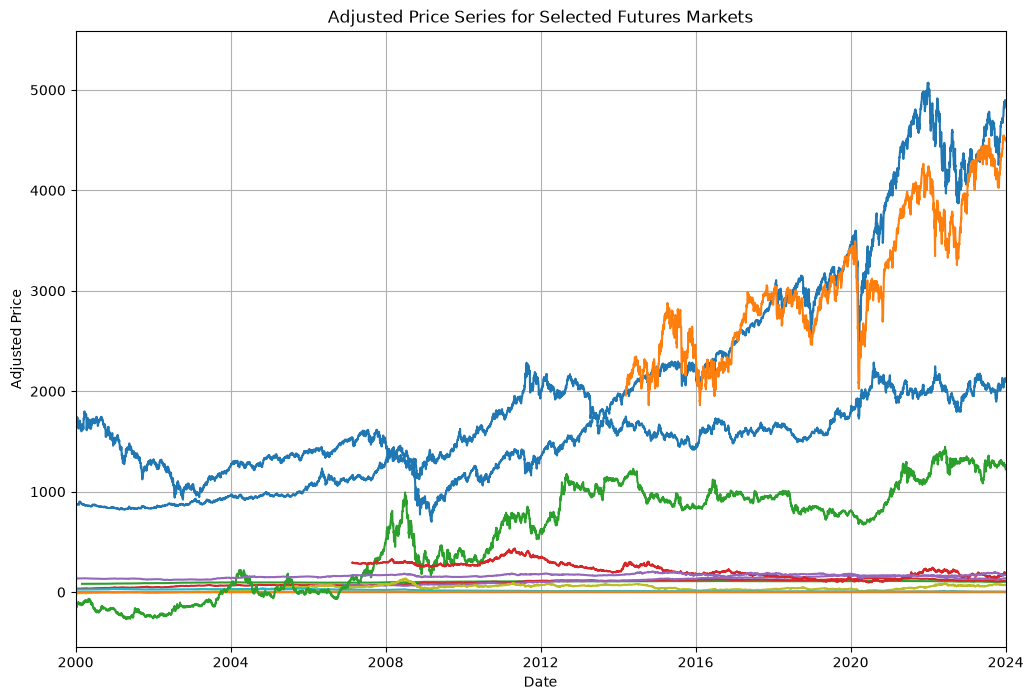

In [2]:
# in this section, we plot some price-adjusted series to visually inspect the data 
# and confirm that the back-adjusted series is behaving as expected.

import matplotlib.pyplot as plt  # Plot the adjusted series for visual inspection.

# List of markets to plot.
selected_markets = ['ES', 'FESX', 'ZT', 'ZN', 'FGBL', '6E', '6J', '6B', 'CL', 'NG', 'GC', 'HG', 'ZS', 'KC', 'LE']  

start_date = pd.Timestamp('2000-01-01') 
end_date = pd.Timestamp('2024-01-01')  

plt.figure(figsize=(12, 8))
plt.title('Adjusted Price Series for Selected Futures Markets')
plt.xlabel('Date')
plt.ylabel('Adjusted Price')
plt.xlim(start_date, end_date)
plt.grid(True)
for market in selected_markets:
    if market in futures:
        plt.plot(futures[market].index, futures[market]['adjusted'], label=market)

## Position sizing

Position size is the instrument's daily dollar risk budget divided by the estimated daily dollar risk of one contract. The guide gives two forms: ATR-based sizing and sizing from percentage-return volatility when a suitable positive price and return series are available.

$$
N_{\mathrm{ATR}} = \frac{rE}{\mathrm{ATR}\,\mathrm{PV}}, \qquad
N_{\mathrm{vol}} = \frac{rE}{\sigma_d P\,\mathrm{PV}}.
$$

- $N$: number of contracts before applying the long or short direction.
- $r$: daily risk budget for this instrument as a fraction of equity (20 basis points = 0.002).$\implies $ _if (r=0.002), the position is sized so its estimated daily move corresponds to (0.2%) of equity._
- $E$: portfolio equity (NAV) in USD, so $rE$ is the instrument's daily budget in dollars.
- $\mathrm{ATR}$: average true range in price points; it uses daily highs, lows, and the previous close.
- $\mathrm{PV}$: value of a one-point move per contract, expressed in USD for use with USD NAV.
- $\sigma_d$: estimated daily volatility of percentage returns, as a decimal (1% = 0.01).
- $P$: current unadjusted futures price in quote units; $\sigma_d P$ estimates daily volatility in price points.

**For this notebook:** the local data are close-only, so true ATR is unavailable. Use the smoothed absolute close-to-close move as a proxy, not as ATR. For volatility sizing, estimate the standard deviation of daily per-contract USD P&L directly: multiply each Panama-adjusted point change by the contract's point value and convert EUR P&L to USD before estimating risk. Do not take percentage returns of Panama-adjusted levels: their levels are arbitrary and can be zero or negative. The proxy and volatility estimate play the same role in sizing but are not numerically equivalent. Matching benchmark risk is a separate portfolio-level step; $r$ is not the benchmark target.

## Backtest parameters

**Signals.** Lookbacks count observed trading sessions. The moving average filters entries only; a filter flip does not exit a trade. The breakout channels exclude the current close and use the same entry and exit lookbacks for longs and shorts. A close-based signal can first trade at the next available close.

**Scheduled resizing.** Count calendar days from the last effective rebalance. At `REBALANCY_FREQ_DAYS = 1`, resize every trading session; at `7`, schedule the next resize seven calendar days later. If due on a non-trading day, move it to the next trading day and count from that new date. For example, a Monday rebalance postponed to Tuesday makes the next weekly rebalance due the following Tuesday. This parameter is for resizing open positions, not for checking daily entry or exit signals. The backtest uses the union of observed futures dates and defers a closed market’s resize to its next close.

**Risk matching.** Estimate each market's daily risk in USD per contract. The volatility version uses trailing standard deviation; the close-move version uses trailing mean absolute P&L, not ATR. Match the corresponding trailing MSCI World risk measure at the portfolio level. A common initial per-market risk budget does not need a separate tuning parameter if it cancels under portfolio scaling before caps.

**Sensitivity.** Keep the guide baseline separate from the draft 50/200 EMA and 20/20 channel settings. Use a common evaluation window and warm-up across variants; the current data audit's 100-session lookback allowance must be revisited before testing the 200-session EMA. The comparison uses the baseline settings. Parameters marked `None` are not modeled in this run.

In [3]:
# strategy details
MA_TYPE = 'ema'  # Use EMA for the baseline and SMA as a sensitivity check.
MA_FAST_SESSIONS = 50  # Set the fast moving-average span.
MA_SLOW_SESSIONS = 100  # Set the slow moving-average span.
EMA_FAST_ALPHA = 2 / (MA_FAST_SESSIONS + 1)  # Derive fast EMA decay from its span.
EMA_SLOW_ALPHA = 2 / (MA_SLOW_SESSIONS + 1)  # Derive slow EMA decay from its span.

ENTRY_LOOKBACK_SESSIONS = 100  # Look back this far for a long or short entry breakout.
EXIT_LOOKBACK_SESSIONS = 50  # Use the shorter channel for exits in either direction.

REBALANCY_FREQ_DAYS = 1  # Count calendar days from the actual resize date; compare with 7.
SIZING_METHOD = 'volatility'  # Compare with 'absolute_move' in a separate run.

# benchmark
INSTRUMENT_RISK_LOOKBACK_SESSIONS = 63  # Estimate contract risk over roughly one quarter.
BENCHMARK_RISK_LOOKBACK_SESSIONS = 63  # Use trailing MSCI World risk as the reference.

TARGET_RISK_MULTIPLIER = 1.0  # Match benchmark risk; compare with 0.75 and 1.25.
MAX_INSTRUMENT_RISK_SHARE = None  # Pending: cap each market's share of estimated portfolio risk.
MAX_GROSS_NOTIONAL_TO_NAV = None  # Pending: set a separate ceiling on gross leverage.
INITIAL_NAV_USD = 100_000  # Set the starting account value for contract sizing.

TRANSACTION_COST_RATE_BP = 0.0005  # Charge 5 bp one way on traded notional, including resizes.
ANNUAL_ROLL_COST_RATE = 0.002  # Charge 0.20% per year on open gross notional as a roll-cost proxy.

CASH_RATE_SERIES = 'FED_FUNDS_RATE__FRED_DFF'  # Use lagged effective fed funds as a USD cash-rate proxy.
CASH_RATE_MULTIPLIER = 1.0  # Credit the full proxy rate on eligible cash in the baseline assumption.
FIXED_ANNUAL_CASH_RATE = 0.01  # Keep the draft 1% assumption as a separate sensitivity case.

## Strategy

Use a moving average to filter trade direction and a breakout to trigger entry. The filter applies only to entries; a change in the filter does not close an existing position.

Let $A_t$ be the Panama-adjusted close for an instrument in session $t$, and let $\mathrm{MA}^{\mathrm{fast}}_t$ and $\mathrm{MA}^{\mathrm{slow}}_t$ be its fast and slow moving averages through that close. The trend filter is

$$
s_t = \begin{cases}
+1, & \text{if } \mathrm{MA}^{\mathrm{fast}}_t > \mathrm{MA}^{\mathrm{slow}}_t, \\
-1, & \text{otherwise.}
\end{cases}
$$

Let $H_t^{(n)}$ and $L_t^{(n)}$ be the highest and lowest adjusted closes over the previous $n$ observed sessions, excluding the current close. Let $n_{\mathrm{entry}}$ and $n_{\mathrm{exit}}$ be `ENTRY_LOOKBACK_SESSIONS` and `EXIT_LOOKBACK_SESSIONS` (100 and 50 in the baseline).

Let $\mathrm{pos}_t \in \{-1,0,+1\}$ denote the position direction immediately after any fills at close $t$. The signal computed at close $t$ determines the direction after fills at the next available close:

$$
\mathrm{pos}_{t+1} = \begin{cases}
+1, & \text{if } \mathrm{pos}_t = 0,\ s_t = +1,\ \text{and } A_t \ge H_t^{(n_{\mathrm{entry}})} \quad \text{(long entry)}, \\
-1, & \text{if } \mathrm{pos}_t = 0,\ s_t = -1,\ \text{and } A_t \le L_t^{(n_{\mathrm{entry}})} \quad \text{(short entry)}, \\
0, & \text{if } \mathrm{pos}_t = +1 \text{ and } A_t \le L_t^{(n_{\mathrm{exit}})} \quad \text{(long exit)}, \\
0, & \text{if } \mathrm{pos}_t = -1 \text{ and } A_t \ge H_t^{(n_{\mathrm{exit}})} \quad \text{(short exit)}, \\
\mathrm{pos}_t, & \text{otherwise.}
\end{cases}
$$

These rules apply to eligible observations within a valid data segment. An exit goes flat rather than reversing immediately. Position direction is checked daily; contract count is a separate sizing decision, and the rebalance schedule governs resizing of open positions. The adjusted point move $A_{t+1}-A_t$ belongs to the position held over that interval, before the fill at $t+1$. A new position filled at close $t+1$ starts earning P&L after that close.

The signal calculation starts flat in each segment and does not carry pending orders across a gap. An actual holding is kept until the next available mark and then closed, as described below.

In [4]:
# Define an EMA helper for one price series and a chosen smoothing span.
def ema(series, span):  
    """Return the recursive EMA after at least `span` observations."""  
    
    # Apply alpha=2/(span+1) and suppress incomplete warm-up values.
    return series.ewm(span=span, adjust=False, min_periods=span).mean() 

    
# Build the directional filter; * makes ma_type keyword-only.
def trend_filter(series, fast_span, slow_span, *, ma_type='ema'):  
    """Return +1 above the slow average, -1 otherwise, and missing during warm-up."""
    
     # Require positive spans with the fast average shorter than the slow one.  
    if not 0 < fast_span < slow_span: 
        raise ValueError('Moving-average spans must satisfy 0 < fast < slow') 
    
    # is exponenial moving average, or simple moving average 
    if ma_type == 'ema':  
        fast = ema(series, fast_span) 
        slow = ema(series, slow_span)  
    # simple moving average, or any other type of moving average that is not supported
    elif ma_type == 'sma': 
        fast = series.rolling(fast_span).mean()  # Average the most recent fast_span closes equally.
        slow = series.rolling(slow_span).mean()  # Average the most recent slow_span closes equally.
    else:  
        raise ValueError(f'Unsupported moving-average type: {ma_type}')  # Tell the caller which parameter is invalid.
    return fast.gt(slow).astype('int8').mul(2).sub(1).where(fast.notna() & slow.notna())  # Map fast>slow to +1, ties/fast<slow to -1; keep warm-up missing.

# Define signal inputs; price and windows are positional.
def position(series, fast_span, slow_span, entry_lookback, exit_lookback,  
             long_only=False, short_only=False, *, ma_type='ema', segment=None, eligible=None): 
    """
    Return direction immediately after each close, not the contract count.  # Document output as direction rather than sizing.

    Pass ordered adjusted closes and, for audited data, their aligned segment  # Explain expected input format to future callers.
    labels and eligibility mask. Without those, assume one eligible segment.  # Describe convenient defaults for small examples.
    """
    # checks
    
     # The two restrictions cannot both be satisfied.
    if long_only and short_only: 
        raise ValueError('Choose at most one direction restriction') 
    
     # Each breakout channel needs at least one past observation.
    if entry_lookback < 1 or exit_lookback < 1: 
        raise ValueError('Breakout lookbacks must be positive')  
    if not series.index.is_unique or not series.index.is_monotonic_increasing:  
        raise ValueError('Closes must be unique and chronologically ordered')
    
    # Treat all rows as one segment when no gap labels are given.
    segment = pd.Series(0, index=series.index) if segment is None else segment  
    
    # Default to tradeable rows for standalone examples.
    eligible = pd.Series(True, index=series.index) if eligible is None else eligible
    
     # Require aligned, complete control series.
    if any(not series.index.equals(values.index) or values.isna().any() for values in (segment, eligible)): 
        raise ValueError('Segment and eligibility must align with closes and contain no missing values')  

    # end of checks
    
    
    positions = []
    
     # Process contiguous runs separately; never roll signals through a gap.
    for _, closes in series.groupby(segment.ne(segment.shift()).cumsum(), sort=False):
        
        # Compute the MA direction using only this segment. 
        trend = trend_filter(closes, fast_span, slow_span, ma_type=ma_type) 
        
        # Exclude today's close from the entry channel.
        entry = closes.shift(1).rolling(entry_lookback) 
        
        # Exclude today's close from the exit channel too. 
        exit_channel = closes.shift(1).rolling(exit_lookback)  
        
        # Long if trend is positive and close reaches prior rolling high.
        long_entry = trend.eq(1) & closes.ge(entry.max())  
        
        # Short if trend is negative and close reaches prior rolling low.
        short_entry = trend.eq(-1) & closes.le(entry.min()) 
        
        # Exit a long at or below the previous exit-window low.
        long_exit = closes.le(exit_channel.min())  
        
        # Exit a short at or above the previous exit-window high.
        short_exit = closes.ge(exit_channel.max())

        # Begin each segment flat, so no signal or holding survives a data break.
        next_position = 0 
        
        # Pair each date with its permission and four rule flags.
        rules = zip(eligible.loc[closes.index], long_entry, short_entry, long_exit, short_exit)
        
        # Apply the finite-state rules in chronological order.
        for can_trade, enter_long, enter_short, exit_long, exit_short in rules: 
            if not can_trade:  # Do not trade during the data-quality warm-up.
                next_position = 0  # Reset direction while the instrument is ineligible.
                positions.append(0)
                continue  # Skip signal updates for this date.
            
             # Today's held direction is the order triggered by the prior close.
            positions.append(next_position)
            if next_position == 0:  
                if enter_long and not short_only:  
                    next_position = 1  
                elif enter_short and not long_only: 
                    next_position = -1  #
            # Check only the exit channel for the open direction.
            elif (next_position == 1 and exit_long) or (next_position == -1 and exit_short):  
                # Queue a flat position; a reversal needs a later entry signal.
                next_position = 0  
                
                
    return pd.Series(positions, index=series.index, dtype='int8', name='position')

In [5]:
from functools import lru_cache

@lru_cache(maxsize=8)
def signal_directions(ma_type, fast, slow, entry, exit):
    min_history = max(MIN_HISTORY, BASE_HISTORY_SESSIONS + max(slow, entry, exit))
    return {
        market: position(
            panel['adjusted'], fast, slow, entry, exit, ma_type=ma_type, segment=panel['segment'],
            eligible=panel.groupby('segment').cumcount().add(1).ge(min_history),
        )
        for market, panel in futures.items()
    }

## Equities benchmark

Estimate ETF returns by applying the annual total expense ratio (TER) to MSCI World USD Net Total Return. The fee compounds over elapsed calendar days, including weekends and holidays. This is a fee-only estimate, not observed ETF performance.

In [6]:
def estimate_etf_returns(index_returns, annual_ter):
    """Apply a decimal annual TER to simple returns on a sorted, unique DatetimeIndex.

    Each return covers the interval since the previous index date. Keep the
    initial NaN from pct_change() so the first interval has a start date.
    """
    if not 0 <= annual_ter < 1:
        raise ValueError('annual_ter must be in [0, 1), e.g. 0.002 for 0.20%')

    dates = index_returns.index
    if not isinstance(dates, pd.DatetimeIndex) or dates.hasnans or not dates.is_unique or not dates.is_monotonic_increasing:
        raise ValueError('index_returns must have a sorted, unique DatetimeIndex with no missing dates')

    elapsed_days = dates.to_series().diff() / pd.Timedelta(days=1)
    fee_factor = (1 - annual_ter) ** (elapsed_days / 365)
    return ((1 + index_returns) * fee_factor - 1).rename('estimated_etf_return')

## Backtest and comparison

This research run uses fractional contracts. Open signals receive equal standalone risk before scaling their combined trailing P&L risk to MSCI World. Sizing uses risk estimates and NAV from before the fill date.

The portfolio calendar is the union of observed futures dates. A market without a mark cannot trade; a scheduled resize waits for its next close. For a gap over seven calendar days, keep the existing holding until its next mark, book the full adjusted point change since the prior mark, and close it there with the usual transaction cost. The multi-day change is not used as a one-session risk move; the portfolio risk matrix treats the missing component as zero. The displayed gap-exit table identifies affected positions and estimated P&L and costs. If no later mark exists, the holding remains open at its last mark rather than disappearing; any unobserved P&L remains unknown.

**Gap limitation:** the next provider mark is only a valuation and assumed exit proxy, not a verified executable price. Cross-gap adjusted differences assume the provider's roll adjustments capture the intervening contract changes; missing marks, roll execution, EUR conversion timing and costs may make actual P&L different. The data cannot independently reconstruct those details. This rule is a disclosed estimate, not a verified liquidation. Cash earns the full lagged USD rate on NAV using ACT/360. Trades pay 5 bp one way on active-contract notional. The baseline roll-cost proxy is 0.20% per year on prior open gross notional, not a charge on specific roll dates; position caps are not modeled.

Both curves start at 100 on the first shared close with valid benchmark and instrument risk and at least one eligible market, using information available at that close without regard to signal direction. Fills occur no earlier than the next market close, with their costs included. `cash_start_comparison` separately retains the earlier first-shared-close, cash-start scenario under the same gap policy. Full equities applies a 0.10% annual ETF TER to the MSCI World USD Net Total Return index, which reinvests dividends net of withholding taxes but does not include fund fees. This is not observed ETF performance.

In [7]:
EQUITY_ETF_TER = 0.001

def trailing_risk(values, window):
    if SIZING_METHOD == 'volatility':
        return values.rolling(window).std()
    if SIZING_METHOD == 'absolute_move':
        return values.abs().rolling(window).mean()
    raise ValueError(f'Unsupported sizing method: {SIZING_METHOD}')

usd_moves, risk_moves, notionals, instrument_risk, segment_starts = {}, {}, {}, {}, {}
for market, panel in futures.items():
    spec = contracts.loc[market]
    usd_point_value = spec.point_value
    if spec.currency == 'EUR':
        usd_point_value *= eurusd.reindex(panel.index, method='ffill', tolerance=pd.Timedelta(days=5))

    segment = panel['segment']
    move = panel['adjusted'].groupby(segment).diff() * usd_point_value
    usd_moves[market] = panel['adjusted'].diff() * usd_point_value
    risk_moves[market] = move
    notionals[market] = panel['active'].abs() * usd_point_value
    instrument_risk[market] = move.groupby(segment).transform(
        lambda values: trailing_risk(values, INSTRUMENT_RISK_LOOKBACK_SESSIONS)
    )
    segment_starts[market] = segment.ne(segment.shift())

moves = pd.DataFrame(usd_moves).fillna(0)
dates = moves.index
notional = pd.DataFrame(notionals).reindex(dates)
observed = notional.notna().to_numpy()
notional = notional.fillna(0).to_numpy()
reset = pd.DataFrame(segment_starts).reindex(dates).eq(True).to_numpy()
prior_notional = pd.DataFrame(notionals).reindex(dates).ffill().shift(1).fillna(0).to_numpy()
contract_risk_at_close = pd.DataFrame(instrument_risk).reindex(dates).ffill()
contract_risk = contract_risk_at_close.shift(1).to_numpy()
benchmark_risk_at_close = trailing_risk(benchmark.pct_change(), BENCHMARK_RISK_LOOKBACK_SESSIONS)
benchmark_risk_at_close = benchmark_risk_at_close.reindex(dates, method='ffill')
benchmark_risk = benchmark_risk_at_close.shift(1).to_numpy()
cash_rate_at_close = load_level(CASH_RATE_SERIES, 'yield_percent', 'USD').reindex(dates, method='ffill') / 100
cash_rate = cash_rate_at_close.shift(1).to_numpy()
elapsed_days = dates.to_series().diff().dt.days.to_numpy()
daily_moves = moves.to_numpy()
daily_risk_moves = pd.DataFrame(risk_moves).reindex(dates).fillna(0).to_numpy()

first_date = audit['first_eligible_close'].min()
start = dates.get_loc(first_date)
shared_dates = dates[start:].intersection(benchmark.index)
eligible = pd.DataFrame({market: panel['eligible_at_close'] for market, panel in futures.items()})
eligible = eligible.reindex(dates).fillna(False).to_numpy(dtype=bool)
risk_at_close = contract_risk_at_close.to_numpy()
ready = (np.isfinite(benchmark_risk_at_close.to_numpy()) & (benchmark_risk_at_close.to_numpy() > 0)
         & np.isfinite(cash_rate_at_close.to_numpy())
         & (np.arange(len(dates)) + 1 >= INSTRUMENT_RISK_LOOKBACK_SESSIONS)
         & (observed & eligible & np.isfinite(risk_at_close) & (risk_at_close > 0)).any(axis=1))
ready_indices = np.flatnonzero(ready & dates.isin(shared_dates))
if not len(ready_indices):
    raise ValueError('No shared close has sufficient risk and eligible market data')
risk_ready_date = dates[ready_indices[0]]
if risk_ready_date == shared_dates[-1]:
    raise ValueError('No shared observation follows the risk-ready close')
equity_returns = estimate_etf_returns(benchmark.loc[shared_dates[0]:shared_dates[-1]].pct_change(), EQUITY_ETF_TER)
equity_nav = (1 + equity_returns.fillna(0)).cumprod().rename('MSCI World ETF (net of TER)')

def run_comparison(ma_type, fast, slow, entry, exit, rebalance_days, risk_multiplier,
                   transaction_rate, annual_roll_rate, cash_multiplier, *, cash_start=False,
                   return_gap_exits=False, return_attribution=False):
    signals = signal_directions(ma_type, fast, slow, entry, exit)
    direction = pd.DataFrame(signals).reindex(dates).ffill().fillna(0).to_numpy()
    nav = INITIAL_NAV_USD
    holdings = np.zeros(len(futures))
    resize_pending = np.zeros(len(futures), dtype=bool)
    next_resize = first_date
    resize_interval = pd.Timedelta(days=rebalance_days)
    nav_history = [nav]
    gap_exits = []
    if return_attribution:
        position_history = np.zeros((len(dates) - start, len(futures)))
        cash_history = np.zeros(len(dates) - start)
    for i in range(start + 1, len(dates)):
        date = dates[i]
        prior_nav = nav
        if annual_roll_rate:
            gross_notional = np.abs(holdings) @ prior_notional[i]
            nav -= gross_notional * annual_roll_rate * elapsed_days[i] / 365
        for j in np.flatnonzero(reset[i] & (holdings != 0)):
            gap_exits.append((date, list(futures)[j], holdings[j], holdings[j] * daily_moves[i, j],
                              abs(holdings[j]) * notional[i, j] * transaction_rate))
        nav += holdings @ daily_moves[i]
        cash_interest = prior_nav * cash_rate[i] * cash_multiplier * elapsed_days[i] / 360
        nav += cash_interest

        if date >= next_resize:
            resize_pending[:] = True
            next_resize = date + resize_interval

        side = direction[i].copy()
        side[reset[i]] = 0
        trade = observed[i] & (resize_pending | (side != np.sign(holdings)))
        if trade.any():
            risk = contract_risk[i]
            unit_positions = np.divide(side, risk, out=np.zeros_like(risk), where=np.isfinite(risk) & (risk > 0))
            target = np.zeros_like(holdings)
            window = INSTRUMENT_RISK_LOOKBACK_SESSIONS
            if i >= window and unit_positions.any() and np.isfinite(benchmark_risk[i]):
                basket_moves = daily_risk_moves[i - window:i] @ unit_positions
                basket_risk = (basket_moves.std(ddof=1) if SIZING_METHOD == 'volatility'
                               else np.abs(basket_moves).mean())
                if basket_risk > 0:
                    target = unit_positions * (prior_nav * risk_multiplier * benchmark_risk[i] / basket_risk)
            nav -= np.abs(target[trade] - holdings[trade]) @ notional[i, trade] * transaction_rate
            holdings[trade] = target[trade]
            resize_pending[trade] = False

        if not np.isfinite(nav) or nav <= 0:
            raise ValueError(f'Trend-following NAV is not positive and finite on {date.date()}')
        nav_history.append(nav)
        if return_attribution:
            position_history[i - start] = holdings
            cash_history[i - start] = cash_interest

    trend_nav = pd.Series(nav_history, index=dates[start:], name='Futures Trend Following')
    levels = pd.DataFrame({trend_nav.name: trend_nav, equity_nav.name: equity_nav}, index=shared_dates)
    if not cash_start:
        levels = levels.loc[risk_ready_date:]
    initial_nav = trend_nav.loc[levels.index[0]]
    levels = levels.div(levels.iloc[0]).mul(100).rename_axis('date')
    results = [levels]
    if return_gap_exits:
        exits = pd.DataFrame(gap_exits, columns=['date', 'market', 'contracts', 'estimated_pnl_usd', 'exit_cost_usd'])
        results.append(exits)
    if return_attribution:
        mark_dates = dates[start + 1:]
        marks = slice(start + 1, None)
        roll_rate = annual_roll_rate * elapsed_days[marks, None] / 365
        columns = {}
        for side, sign in [('Long', 1), ('Short', -1)]:
            quantity = np.maximum(sign * position_history, 0)
            held = quantity[:-1]
            pnl = sign * held * daily_moves[marks]
            trading = -np.abs(np.diff(quantity, axis=0)) * notional[marks] * transaction_rate
            roll = -held * prior_notional[marks] * roll_rate
            for j, market in enumerate(futures):
                columns[market, side, 'Futures P&L'] = pnl[:, j]
                columns[market, side, 'Trading costs'] = trading[:, j]
                columns[market, side, 'Roll drag'] = roll[:, j]
        columns['Portfolio', 'Unallocated', 'Cash interest'] = cash_history[1:]
        ledger = pd.DataFrame(columns, index=mark_dates)
        ledger.columns.names = ['Market', 'Side', 'Component']
        ledger = ledger.loc[(mark_dates > levels.index[0]) & (mark_dates <= levels.index[-1])]
        results.append(ledger.div(initial_nav).mul(100))
    return tuple(results) if len(results) > 1 else levels

comparison, gap_exits, attribution_ledger = run_comparison(
    MA_TYPE, MA_FAST_SESSIONS, MA_SLOW_SESSIONS, ENTRY_LOOKBACK_SESSIONS, EXIT_LOOKBACK_SESSIONS,
    REBALANCY_FREQ_DAYS, TARGET_RISK_MULTIPLIER, TRANSACTION_COST_RATE_BP,
    ANNUAL_ROLL_COST_RATE, CASH_RATE_MULTIPLIER, return_gap_exits=True, return_attribution=True,
)
cash_start_comparison = run_comparison(
    MA_TYPE, MA_FAST_SESSIONS, MA_SLOW_SESSIONS, ENTRY_LOOKBACK_SESSIONS, EXIT_LOOKBACK_SESSIONS,
    REBALANCY_FREQ_DAYS, TARGET_RISK_MULTIPLIER, TRANSACTION_COST_RATE_BP,
    ANNUAL_ROLL_COST_RATE, CASH_RATE_MULTIPLIER, cash_start=True,
)
print('Risk-ready comparison')
display(comparison)
print('Estimated exits after long gaps')
display(gap_exits)

Risk-ready comparison


,Futures Trend Following,MSCI World ETF (net of TER)
date,,
2001-03-28,100.000000,100.000000
2001-03-29,99.887412,99.045973
2001-03-30,102.404159,99.617020
2001-04-02,102.720540,98.609846
2001-04-03,102.875550,96.176719
...,...,...
2024-03-22,775.182350,481.600387
2024-03-25,777.079792,480.491882
2024-03-26,780.496335,479.666560


Estimated exits after long gaps


,date,market,contracts,estimated_pnl_usd,exit_cost_usd
0,2019-01-03,FESX,-3.09898,211.951649,52.016467
1,2019-01-03,6E,-2.01887,-593.043136,144.677289


### Comparison charts

Rolling five-year returns are cumulative, using the last shared close on or before the five-year anniversary. Rolling one-year correlation uses 252 paired daily returns, not price levels. `SHOW_EVENTS` controls the historical markers on the growth and drawdown charts.

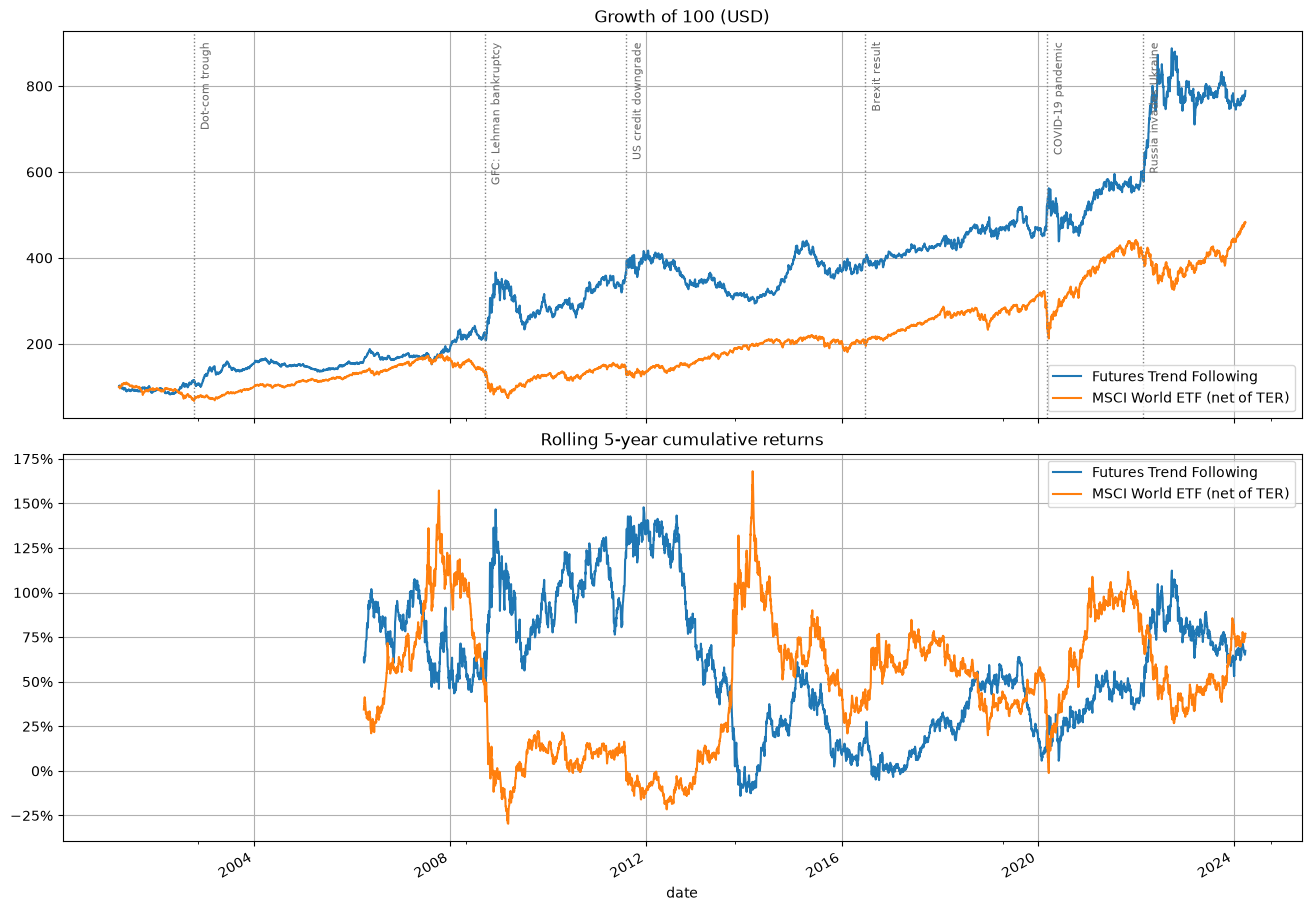

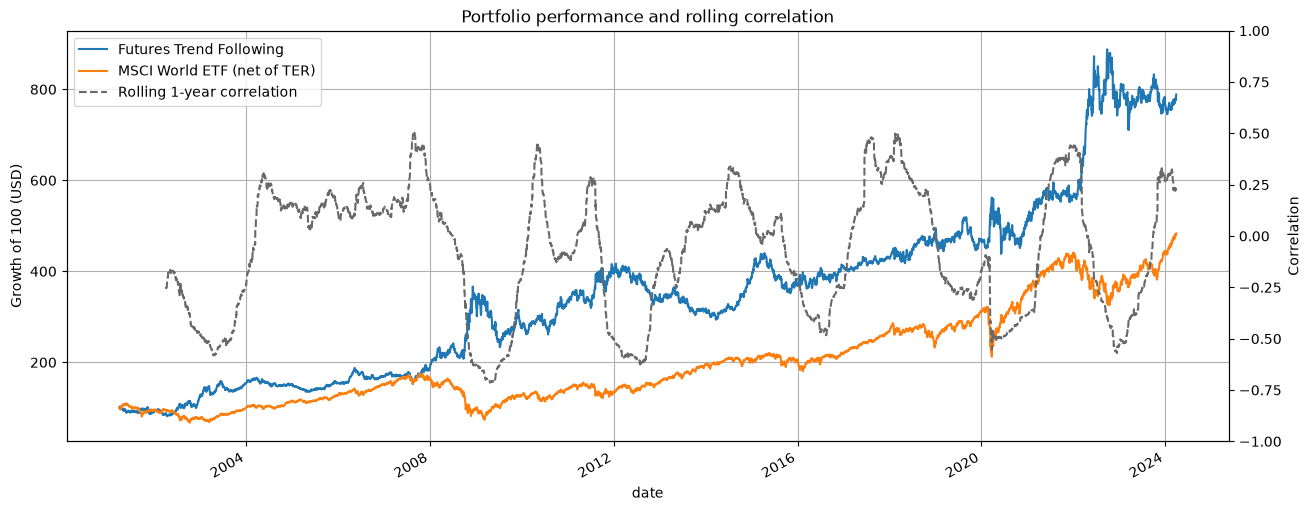

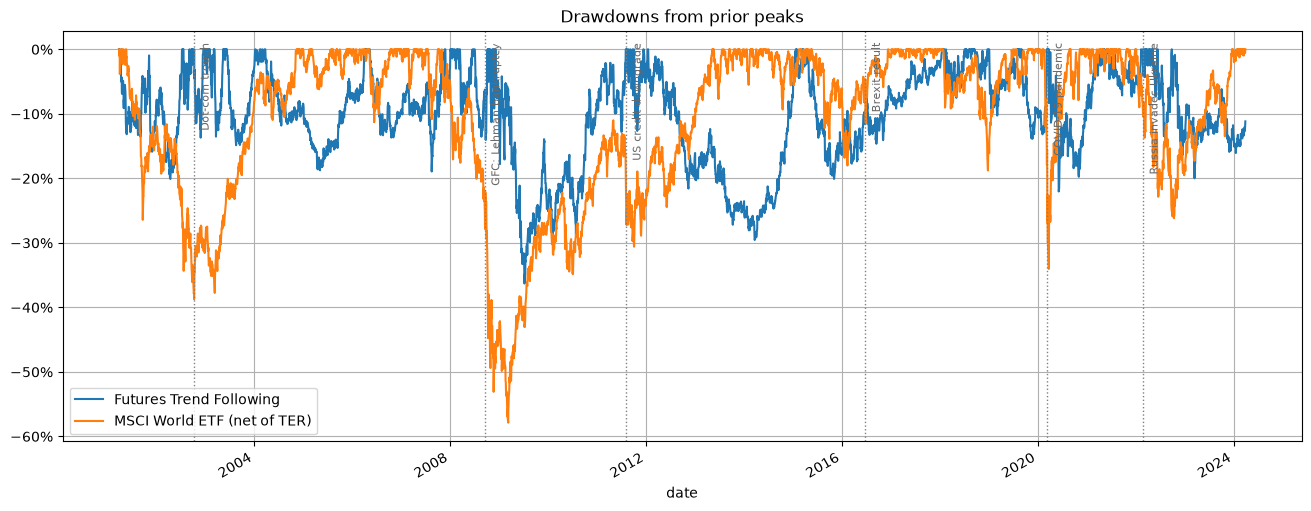

In [8]:
from matplotlib.ticker import PercentFormatter

SHOW_EVENTS = True
EVENTS = {
    '2002-10-09': 'Dot-com trough',
    '2008-09-15': 'GFC: Lehman bankruptcy',
    '2011-08-05': 'US credit downgrade',
    '2016-06-24': 'Brexit result',
    '2020-03-11': 'COVID-19 pandemic',
    '2022-02-24': 'Russia invades Ukraine',
}

def annotate_events(ax):
    if SHOW_EVENTS:
        for day, label in EVENTS.items():
            date = pd.Timestamp(day)
            if comparison.index[0] <= date <= comparison.index[-1]:
                ax.axvline(date, color='gray', linestyle=':', linewidth=1)
                ax.annotate(label, (ax.convert_xunits(date), 0.97), xycoords=ax.get_xaxis_transform(),
                            xytext=(4, 0), textcoords='offset points', rotation=90,
                            va='top', color='dimgray', fontsize=8)

def drawdown(levels):
    return levels / levels.cummax() - 1

def rolling_five_year_returns(levels):
    start_dates = levels.index - pd.DateOffset(years=5)
    start_levels = levels.reindex(start_dates, method='ffill').set_axis(levels.index)
    return levels / start_levels - 1

daily_returns = comparison.pct_change().dropna()
trend, equities = daily_returns.columns
rolling_correlation = daily_returns[trend].rolling(252).corr(daily_returns[equities])

fig, (growth_ax, rolling_ax) = plt.subplots(2, 1, figsize=(13, 9), sharex=True, layout='constrained')
comparison.plot(ax=growth_ax, title='Growth of 100 (USD)', grid=True)
annotate_events(growth_ax)
rolling_five_year_returns(comparison).plot(ax=rolling_ax, title='Rolling 5-year cumulative returns', grid=True)
rolling_ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

fig, performance_ax = plt.subplots(figsize=(13, 5), layout='constrained')
comparison.plot(ax=performance_ax, title='Portfolio performance and rolling correlation', grid=True, legend=False)
performance_ax.set_ylabel('Growth of 100 (USD)')
correlation_ax = performance_ax.twinx()
correlation_ax.plot(rolling_correlation.index, rolling_correlation, color='dimgray', linestyle='--',
                    label='Rolling 1-year correlation')
correlation_ax.set(ylabel='Correlation', ylim=(-1, 1))
performance_ax.legend(handles=performance_ax.lines + correlation_ax.lines, loc='upper left')
plt.show()

fig, drawdown_ax = plt.subplots(figsize=(13, 5), layout='constrained')
drawdown(comparison).plot(ax=drawdown_ax, title='Drawdowns from prior peaks', grid=True, legend=False)
drawdown_ax.legend(loc='lower left')
drawdown_ax.yaxis.set_major_formatter(PercentFormatter(1))
annotate_events(drawdown_ax)
plt.show()

### Summary metrics

Sharpe and Sortino use excess returns over the lagged Fed funds cash proxy; risk ratios and volatility annualize with 252 observations per year. Average drawdown duration counts calendar days from peak to recovery (or to the final date for an open drawdown), with each episode weighted equally. The Ulcer Index is the root mean square of drawdowns.

In [9]:
def cagr(levels):
    years = (levels.index[-1] - levels.index[0]).days / 365.25
    return (levels.iloc[-1] / levels.iloc[0]) ** (1 / years) - 1

def sharpe_ratio(excess_returns):
    risk = excess_returns.std()
    return excess_returns.mean() / risk * np.sqrt(252) if risk > 0 else np.nan

def annualized_volatility(returns):
    return returns.std() * np.sqrt(252)

def sortino_ratio(excess_returns):
    downside = np.sqrt(excess_returns.clip(upper=0).pow(2).mean())
    return excess_returns.mean() / downside * np.sqrt(252) if downside > 0 else np.nan

def ulcer_index(levels):
    return np.sqrt(drawdown(levels).pow(2).mean())

def average_drawdown_duration(levels):
    underwater = drawdown(levels).lt(0)
    previously_underwater = underwater.shift(fill_value=False)
    peaks = levels.index[(underwater & ~previously_underwater).to_numpy().nonzero()[0] - 1]
    ends = levels.index[~underwater & previously_underwater]
    if underwater.iloc[-1]:
        ends = ends.append(levels.index[-1:])
    return np.mean((ends - peaks).days) if len(peaks) else 0.0

def max_drawdown(levels):
    return drawdown(levels).min()

cash_growth = pd.Series(1 + cash_rate * elapsed_days / 360, index=dates).fillna(1).cumprod()

def comparison_summary(levels):
    returns = levels.pct_change().dropna()
    cash_returns = cash_growth.loc[levels.index].pct_change()
    excess_returns = returns.sub(cash_returns.loc[returns.index], axis=0)
    return pd.DataFrame({
        name: {
            'CAGR': cagr(levels[name]),
            'Sharpe ratio': sharpe_ratio(excess_returns[name]),
            'Volatility': annualized_volatility(returns[name]),
            'Sortino ratio': sortino_ratio(excess_returns[name]),
            'Ulcer Index': ulcer_index(levels[name]),
            'Average drawdown duration (days)': average_drawdown_duration(levels[name]),
            'Max drawdown': max_drawdown(levels[name]),
        }
        for name in levels
    })

def format_summary(metrics):
    formatted = metrics.map('{:.2f}'.format)
    percent_rows = ['CAGR', 'Volatility', 'Ulcer Index', 'Max drawdown']
    formatted.loc[percent_rows] = metrics.loc[percent_rows].map('{:.2%}'.format)
    return formatted

summary = comparison_summary(comparison)
print('Risk-ready comparison')
display(format_summary(summary))
print('Earlier cash-start comparison (same gap policy)')
display(format_summary(comparison_summary(cash_start_comparison)))

Risk-ready comparison


,Futures Trend Following,MSCI World ETF (net of TER)
CAGR,9.39%,7.09%
Sharpe ratio,0.51,0.40
Volatility,17.00%,16.26%
Sortino ratio,0.73,0.55
Ulcer Index,12.39%,15.71%
Average drawdown duration (days),73.17,37.85
Max drawdown,-36.30%,-57.87%


Earlier cash-start comparison (same gap policy)


,Futures Trend Following,MSCI World ETF (net of TER)
CAGR,9.36%,6.40%
Sharpe ratio,0.51,0.35
Volatility,16.91%,16.29%
Sortino ratio,0.73,0.49
Ulcer Index,12.33%,16.52%
Average drawdown duration (days),73.17,40.09
Max drawdown,-36.30%,-57.87%


## Comparison with SG Trend

Compare the baseline risk-ready futures portfolio, MSCI World ETF estimate and SG Trend on their common monthly return history. SG Trend uses the net monthly returns in `data/MANAGED_FUTURES_MONTHLY.CSV`, sourced from BarclayHedge. The futures portfolio includes modeled trading costs and cash interest; the equity estimate includes a 0.10% annual TER. These are not identical fee or implementation conventions.

The daily portfolios and cash proxy are sampled at the last shared close of each month; the initial partial month provides only the starting level. A terminal month is excluded unless the benchmark has observations in a later month and the shared portfolio reaches the benchmark's last close of that month. SG Trend uses calendar-month returns, so its exact valuation dates can differ. All curves start at 100 before the first common return. Volatility, Sharpe and Sortino use monthly observations and annualize by 12; ratios use the same lagged Fed funds cash proxy as above. Drawdowns and durations are measured at monthly frequency.

Common monthly returns: 2001-04 to 2024-02 (275 months)


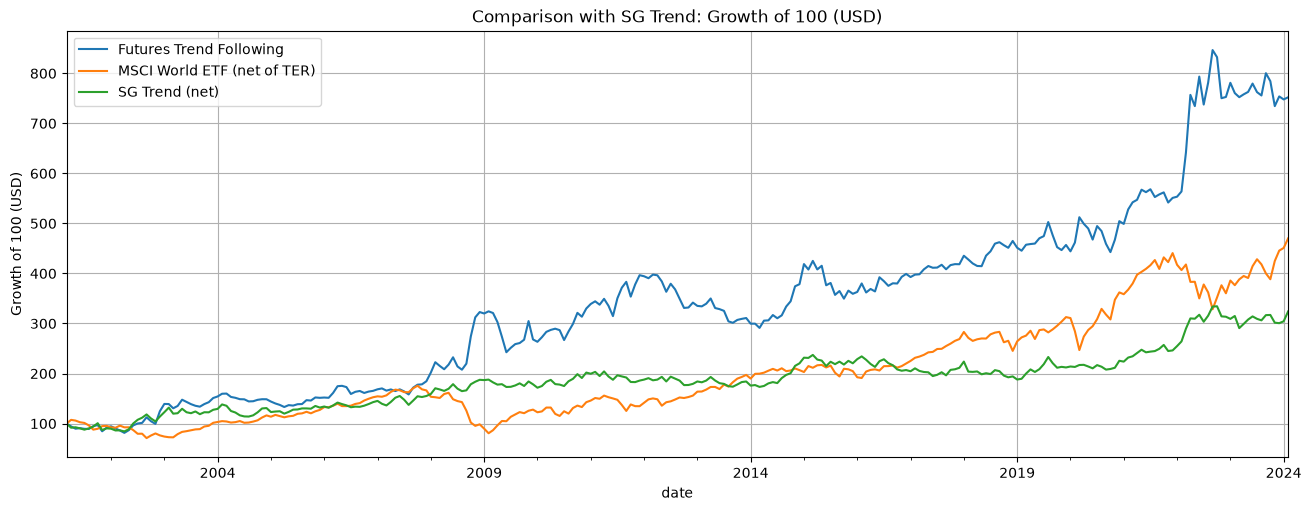

,Futures Trend Following,MSCI World ETF (net of TER),SG Trend (net)
CAGR,9.20%,6.99%,5.26%
Sharpe ratio,0.50,0.41,0.34
Volatility,17.55%,15.63%,13.05%
Sortino ratio,0.89,0.59,0.51
Ulcer Index,9.78%,15.14%,8.71%
Average drawdown duration (days),279.56,276.08,344.04
Max drawdown,-26.80%,-54.09%,-20.74%


In [10]:
def sg_monthly_comparison(daily_levels, daily_cash, sg_returns, benchmark_levels):
    monthly_levels = daily_levels.resample('ME').last()
    monthly_cash = daily_cash.reindex(daily_levels.index).resample('ME').last()
    last_month = daily_levels.index[-1].to_period('M')
    benchmark_month = benchmark_levels.loc[benchmark_levels.index.to_period('M') == last_month]
    if (benchmark_levels.index[-1].to_period('M') <= last_month or benchmark_month.empty
            or daily_levels.index[-1] < benchmark_month.index[-1]):
        monthly_levels = monthly_levels.iloc[:-1]
        monthly_cash = monthly_cash.iloc[:-1]

    sg_returns = sg_returns.dropna().copy()
    sg_returns.index = sg_returns.index.to_period('M').to_timestamp('M')
    if (sg_returns.empty or not sg_returns.index.is_unique or not sg_returns.index.is_monotonic_increasing
            or not np.isfinite(sg_returns).all() or (sg_returns <= -1).any()):
        raise ValueError('SG Trend returns must be unique, sorted, finite monthly returns greater than -100%')
    if len(monthly_levels) < 2:
        raise ValueError('Not enough complete monthly portfolio observations')

    first_return = max(monthly_levels.index[1], sg_returns.index[0])
    last_return = min(monthly_levels.index[-1], sg_returns.index[-1])
    if first_return > last_return:
        raise ValueError('No overlapping monthly returns for SG Trend and the portfolios')
    baseline = first_return - pd.offsets.MonthEnd(1)
    months = pd.date_range(baseline, last_return, freq='ME')
    portfolio = monthly_levels.reindex(months)
    cash = monthly_cash.reindex(months)
    sg = sg_returns.reindex(months[1:])
    if portfolio.isna().any().any() or cash.isna().any() or sg.isna().any():
        raise ValueError('Missing observations within the common monthly comparison period')
    levels = portfolio.div(portfolio.iloc[0]).mul(100)
    levels['SG Trend (net)'] = pd.concat([pd.Series([100.0], index=months[:1]),
                                         100 * (1 + sg).cumprod()])
    return levels.rename_axis('date'), cash.div(cash.iloc[0])

def monthly_comparison_summary(levels, cash):
    returns = levels.pct_change().iloc[1:]
    excess = returns.sub(cash.pct_change().iloc[1:], axis=0)
    metrics = {}
    for name in levels:
        risk = excess[name].std()
        downside = np.sqrt(excess[name].clip(upper=0).pow(2).mean())
        metrics[name] = {
            'CAGR': cagr(levels[name]),
            'Sharpe ratio': excess[name].mean() / risk * np.sqrt(12) if risk > 0 else np.nan,
            'Volatility': returns[name].std() * np.sqrt(12),
            'Sortino ratio': excess[name].mean() / downside * np.sqrt(12) if downside > 0 else np.nan,
            'Ulcer Index': ulcer_index(levels[name]),
            'Average drawdown duration (days)': average_drawdown_duration(levels[name]),
            'Max drawdown': max_drawdown(levels[name]),
        }
    return pd.DataFrame(metrics)

managed_futures = pd.read_csv(Path('data') / 'MANAGED_FUTURES_MONTHLY.CSV', parse_dates=['date'])
sg_returns = managed_futures.set_index('date')['sg_trend_net']
sg_comparison, sg_cash = sg_monthly_comparison(comparison, cash_growth, sg_returns, benchmark)
print(f'Common monthly returns: {(sg_comparison.index[0] + pd.offsets.MonthEnd(1)):%Y-%m} to '
      f'{sg_comparison.index[-1]:%Y-%m} ({len(sg_comparison) - 1} months)')
fig, ax = plt.subplots(figsize=(13, 5), layout='constrained')
sg_comparison.plot(ax=ax, title='Comparison with SG Trend: Growth of 100 (USD)', grid=True)
ax.set_ylabel('Growth of 100 (USD)')
plt.show()
display(format_summary(monthly_comparison_summary(sg_comparison, sg_cash)))

---

## Interactive Benchmark

Run the cell below to update the growth chart and summary table. Controls are grouped by moving averages, breakout signals, portfolio sizing, and costs and cash. Sliders recalculate on release, replacing the existing chart and table. The MSCI World comparison (0.10% annual TER), comparison dates, and risk-free series used for the ratios stay fixed. Longer signal lookbacks extend each market's warm-up.

Transaction cost is one-way basis points of traded notional. Roll cost is an annual percentage accrued over calendar days on the prior close's open gross notional, not a charge on specific roll dates. Cash multiplier scales the interest credited to the futures strategy.

In [11]:
from html import escape
from io import BytesIO

import ipywidgets as widgets
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure

slider_style = {'description_width': '150px'}

def int_slider(label, value, minimum, maximum):
    return widgets.IntSlider(description=label, value=value, min=minimum, max=maximum,
                             continuous_update=False, style=slider_style)

def float_slider(label, value, maximum, step):
    return widgets.FloatSlider(description=label, value=value, min=0, max=maximum, step=step,
                               continuous_update=False, style=slider_style, readout_format='.2f')

controls = {
    'ma_type': widgets.Dropdown(description='Moving average', options=[('EMA', 'ema'), ('SMA', 'sma')],
                                value=MA_TYPE, style=slider_style),
    'fast': int_slider('Fast MA (sessions)', MA_FAST_SESSIONS, 2, 250),
    'slow': int_slider('Slow MA (sessions)', MA_SLOW_SESSIONS, 3, 300),
    'entry': int_slider('Entry lookback', ENTRY_LOOKBACK_SESSIONS, 1, 300),
    'exit': int_slider('Exit lookback', EXIT_LOOKBACK_SESSIONS, 1, 300),
    'rebalance_days': int_slider('Rebalance (days)', REBALANCY_FREQ_DAYS, 1, 30),
    'risk_multiplier': float_slider('Target risk multiplier', TARGET_RISK_MULTIPLIER, 2, 0.05),
    'transaction_bp': float_slider('Trading cost (bp)', TRANSACTION_COST_RATE_BP * 10_000, 50, 0.5),
    'roll_percent': float_slider('Annual roll cost (%)', ANNUAL_ROLL_COST_RATE * 100, 5, 0.05),
    'cash_multiplier': float_slider('Cash rate multiplier', CASH_RATE_MULTIPLIER, 2, 0.05),
}

chart_image = widgets.Image(format='png', layout=widgets.Layout(width='100%', max_width='1200px'))
summary_table = widgets.HTML()
update_status = widgets.HTML()

def update_interactive_comparison(change=None):
    parameters = {name: control.value for name, control in controls.items()}
    if parameters['fast'] >= parameters['slow']:
        update_status.value = 'Fast MA must be shorter than Slow MA. Previous results are shown.'
        return
    transaction_bp = parameters.pop('transaction_bp')
    roll_percent = parameters.pop('roll_percent')
    update_status.value = 'Updating...'
    try:
        levels = run_comparison(**parameters, transaction_rate=transaction_bp / 10_000,
                                annual_roll_rate=roll_percent / 100)
    except ValueError as error:
        update_status.value = f'{escape(str(error))} Previous results are shown.'
        return
    fig = Figure(figsize=(12, 5), layout='constrained')
    canvas = FigureCanvasAgg(fig)
    ax = fig.subplots()
    levels.plot(ax=ax, title='Growth of 100 (USD)', grid=True)
    annotate_events(ax)
    with BytesIO() as buffer:
        canvas.print_png(buffer)
        chart_image.value = buffer.getvalue()
    summary_table.value = format_summary(comparison_summary(levels)).to_html()
    update_status.value = ''

def control_group(title, *keys):
    group_controls = [controls[key] for key in keys]
    for control in group_controls:
        control.layout = widgets.Layout(flex='1 1 270px', min_width='250px', max_width='340px',
                                        width='auto', margin='0')
    heading = widgets.HTML(f'<strong>{title}</strong>', layout=widgets.Layout(margin='0'))
    row = widgets.HBox(group_controls, layout=widgets.Layout(flex_flow='row wrap', grid_gap='0 12px'))
    return widgets.VBox([heading, row], layout=widgets.Layout(margin='0 0 2px 0'))

for control in controls.values():
    control.observe(update_interactive_comparison, names='value')
update_interactive_comparison()
display(widgets.VBox([
    control_group('Moving averages', 'ma_type', 'fast', 'slow'),
    control_group('Breakout signals', 'entry', 'exit'),
    control_group('Portfolio sizing', 'rebalance_days', 'risk_multiplier'),
    control_group('Costs and cash', 'transaction_bp', 'roll_percent', 'cash_multiplier'),
    update_status, chart_image, summary_table,
]))

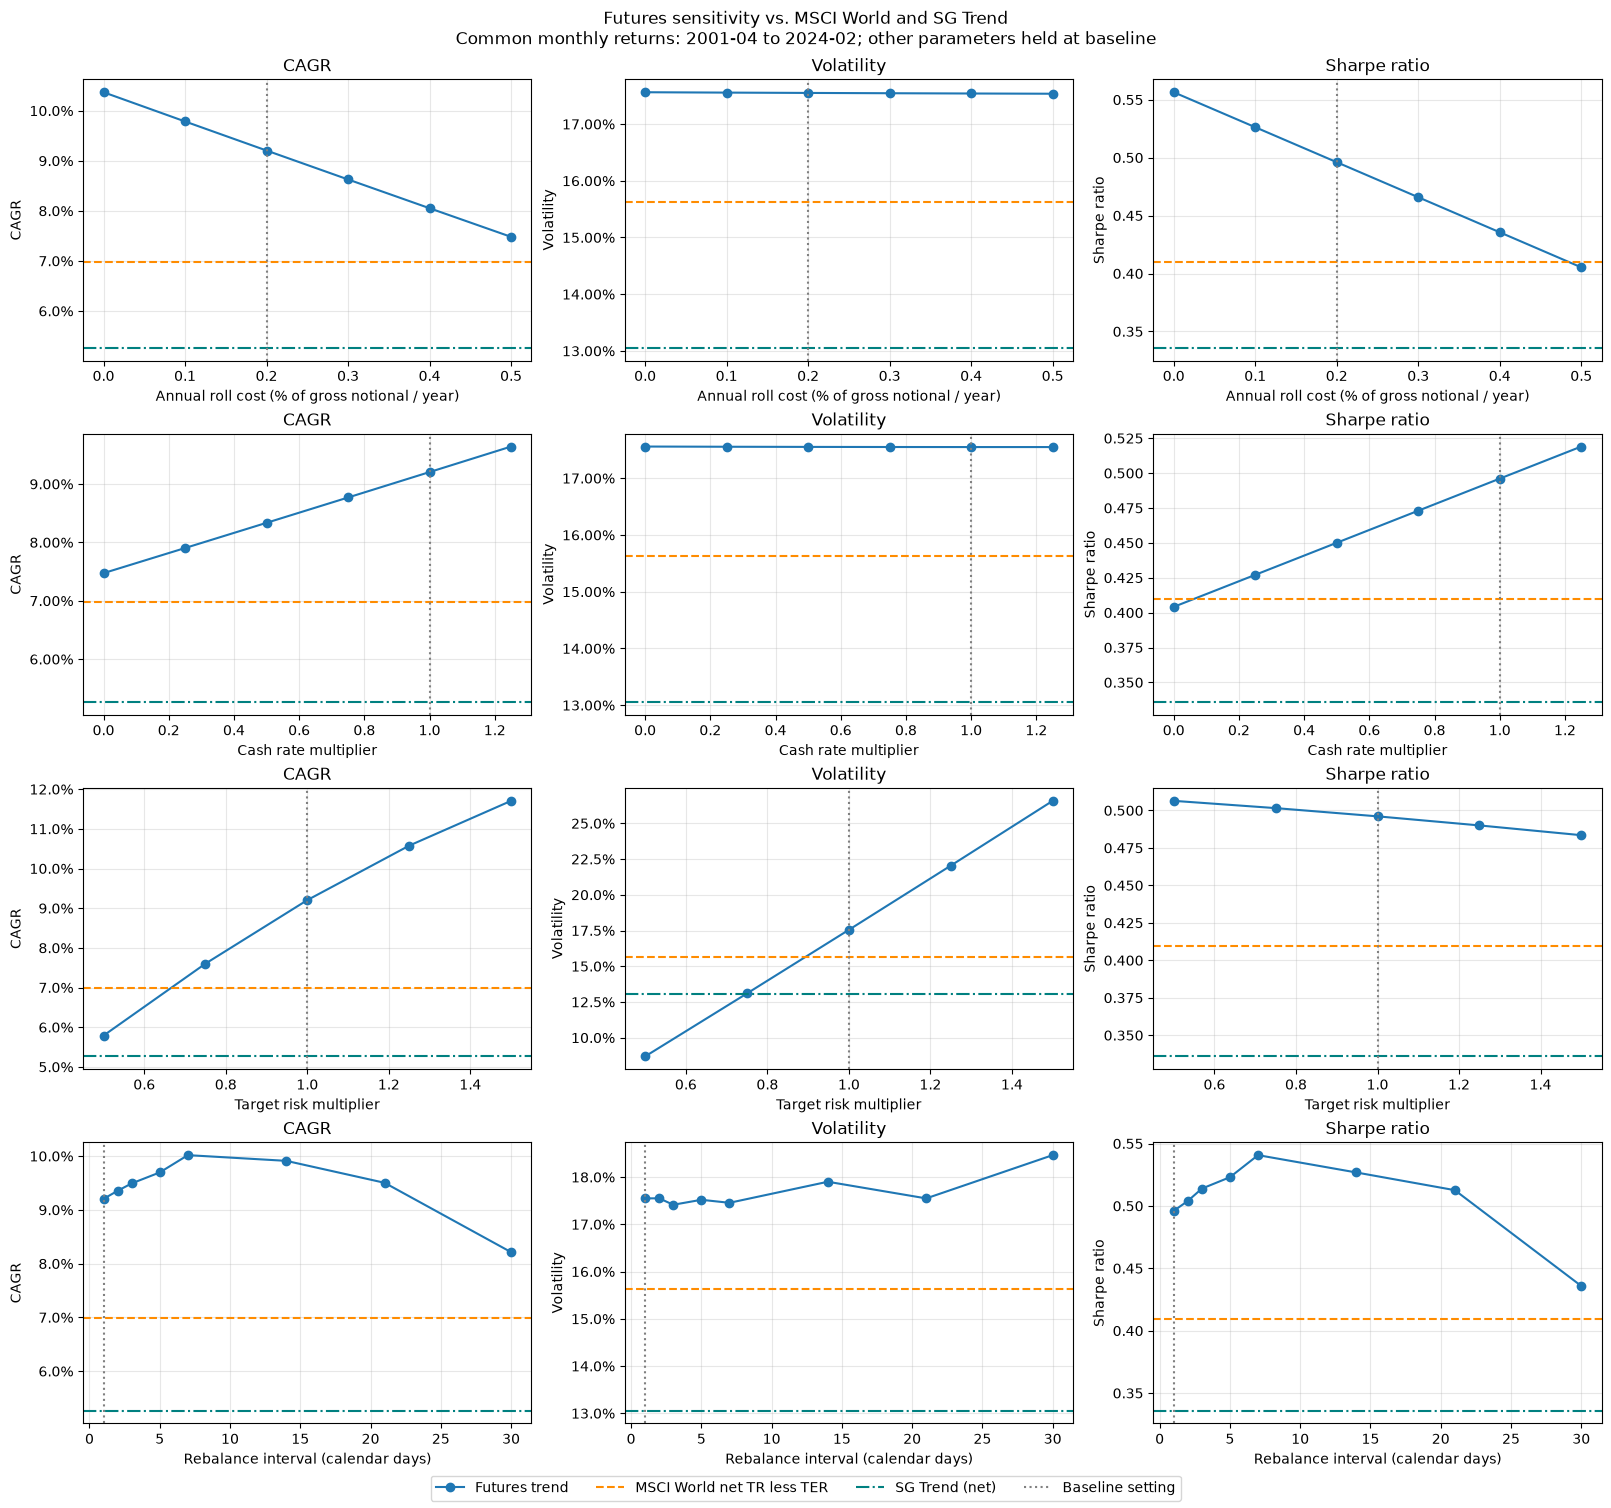

In [12]:
# Vary one parameter at a time; all other settings remain at their baseline values.
sensitivity_baseline = {
    'ma_type': MA_TYPE, 'fast': MA_FAST_SESSIONS, 'slow': MA_SLOW_SESSIONS,
    'entry': ENTRY_LOOKBACK_SESSIONS, 'exit': EXIT_LOOKBACK_SESSIONS,
    'rebalance_days': REBALANCY_FREQ_DAYS, 'risk_multiplier': TARGET_RISK_MULTIPLIER,
    'transaction_rate': TRANSACTION_COST_RATE_BP, 'annual_roll_rate': ANNUAL_ROLL_COST_RATE,
    'cash_multiplier': CASH_RATE_MULTIPLIER,
}
sensitivity_specs = [
    ('annual_roll_rate', 'Annual roll cost (% of gross notional / year)',
     [0, 0.001, 0.002, 0.003, 0.004, 0.005], 100),
    ('cash_multiplier', 'Cash rate multiplier', [0, 0.25, 0.5, 0.75, 1, 1.25], 1),
    ('risk_multiplier', 'Target risk multiplier', [0.5, 0.75, 1, 1.25, 1.5], 1),
    ('rebalance_days', 'Rebalance interval (calendar days)', [1, 2, 3, 5, 7, 14, 21, 30], 1),
]
sensitivity_metrics = ['CAGR', 'Volatility', 'Sharpe ratio']
benchmark_metrics = monthly_comparison_summary(sg_comparison, sg_cash).loc[sensitivity_metrics]
sensitivity_results = {}
for parameter, label, values, scale in sensitivity_specs:
    values = sorted(set(values + [sensitivity_baseline[parameter]]))
    rows = []
    for value in values:
        parameters = {**sensitivity_baseline, parameter: value}
        levels = run_comparison(**parameters)
        monthly_levels, monthly_cash = sg_monthly_comparison(levels, cash_growth, sg_returns, benchmark)
        rows.append(monthly_comparison_summary(monthly_levels, monthly_cash)
                    .loc[sensitivity_metrics, 'Futures Trend Following'])
    sensitivity_results[parameter] = pd.DataFrame(rows, index=pd.Index(values, name=parameter))

sensitivity_fig, sensitivity_axes = plt.subplots(4, 3, figsize=(16, 15), layout='constrained')
first_month = sg_comparison.index[0] + pd.offsets.MonthEnd(1)
last_month = sg_comparison.index[-1]
sensitivity_fig.suptitle('Futures sensitivity vs. MSCI World and SG Trend\n'
                         f'Common monthly returns: {first_month:%Y-%m} to {last_month:%Y-%m}; '
                         'other parameters held at baseline')
for row, (parameter, label, values, scale) in enumerate(sensitivity_specs):
    results = sensitivity_results[parameter]
    for column, metric in enumerate(sensitivity_metrics):
        ax = sensitivity_axes[row, column]
        ax.plot(results.index.to_numpy() * scale, results[metric], marker='o', label='Futures trend')
        ax.axhline(benchmark_metrics.loc[metric, 'MSCI World ETF (net of TER)'],
                   color='darkorange', linestyle='--', label='MSCI World net TR less TER')
        ax.axhline(benchmark_metrics.loc[metric, 'SG Trend (net)'],
                   color='teal', linestyle='-.', label='SG Trend (net)')
        ax.axvline(sensitivity_baseline[parameter] * scale, color='gray', linestyle=':', label='Baseline setting')
        ax.set(xlabel=label, ylabel=metric, title=metric)
        ax.grid(True, alpha=0.3)
        if metric in ('CAGR', 'Volatility'):
            ax.yaxis.set_major_formatter(PercentFormatter(1))
handles, labels = sensitivity_axes[0, 0].get_legend_handles_labels()
sensitivity_fig.legend(handles, labels, loc='outside lower center', ncol=4)
plt.show()

## Why this strategy differs from SG Trend

On the common monthly sample (April 2001–February 2024), the baseline and SG Trend had **0.72 return correlation**, but the baseline was more volatile (**17.55% vs. 13.05%** annualized). In 2008 it gained **74.9% vs. 20.9%**, then lost **16.9% vs. 4.8%** in 2009. A few large differences like these can leave a lasting gap in compounded wealth.

The backtest runs one EMA-filtered breakout rule on 15 fixed candidate markets with staggered eligibility and sizes the portfolio against equity risk. [SG Trend](https://wholesale.banking.societegenerale.com/en/prime-services-indices/) averages the net returns of trend-following managers and reconstitutes annually; it does not implement this rule or target this risk level. Differences in markets, signal speeds, sizing, collateral and fees can all matter. The study models trading and roll costs but no manager fee. These are plausible explanations, not an attribution or evidence of superior signal quality.

## Attribution by market and position side

This decomposes the baseline futures strategy over the risk-ready comparison window. Contributions are in **percentage points of cumulative return**: each dollar gain, loss or cost is divided by NAV at the first shared close. They add up to the strategy’s total return, not its CAGR. This is attribution of the actual portfolio, not separate long-only or short-only backtests.

Futures P&L and the roll-cost proxy follow the position held into each mark. Trading costs follow the side traded; on a reversal the old side pays for closing and the new side pays for opening. Collateral interest is shown separately at portfolio level. Gap exits retain the backtest’s estimated marks and costs.

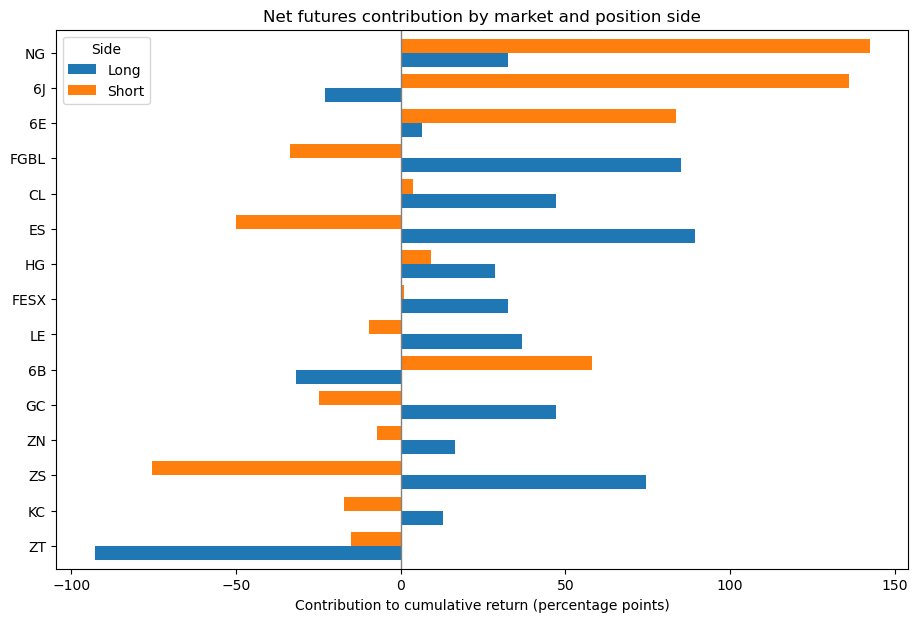

Component,Futures P&L,Trading costs,Roll drag,Cash interest,Net
Side,,,,,
Long,629.71,-209.31,-59.28,0.00,361.11
Short,341.73,-111.81,-29.76,0.00,200.15
Portfolio cash,0.00,0.00,0.00,127.46,127.46
Total,971.43,-321.13,-89.05,127.46,688.72


Side             Long                                      Short  \
Component Futures P&L Trading costs Roll drag    Net Futures P&L   
Market                                                             
NG              33.67         -1.01     -0.25  32.41      145.70   
6J             -16.64         -5.09     -1.34 -23.08      148.90   
6E              14.28         -6.25     -1.70   6.33       91.47   
FGBL           104.81        -15.11     -4.76  84.94      -24.96   
CL              51.27         -3.26     -0.94  47.08        6.14   
ES              99.12         -7.34     -2.40  89.38      -47.73   
HG              32.94         -3.39     -0.90  28.65       12.60   
FESX            35.57         -2.38     -0.66  32.53        2.33   
LE              46.21         -7.19     -2.09  36.94       -4.51   
6B             -20.38         -9.12     -2.40 -31.90       67.30   
GC              55.19         -6.48     -1.65  47.05      -21.43   
ZN              38.54        -17.39     -4.83  16.33        4.77   
ZS              80.20         -4.55     -1.16  74.49      -70.52   
KC              14.86         -1.59     -0.35  12.92      -13.65   
ZT              60.07       -119.17    -33.86 -92.96       45.33   

Side                                       
Component Trading costs Roll drag     Net  
Market                                     
NG                -2.64     -0.71  142.34  
6J                -9.92     -2.90  136.08  
6E                -5.94     -1.99   83.54  
FGBL              -7.06     -1.75  -33.76  
CL                -1.87     -0.44    3.83  
ES                -1.96     -0.47  -50.15  
HG                -2.82     -0.73    9.05  
FESX              -0.97     -0.29    1.07  
LE                -4.16     -0.99   -9.65  
6B                -7.13     -2.16   58.01  
GC                -2.85     -0.68  -24.96  
ZN                -9.43     -2.55   -7.21  
ZS                -4.13     -1.02  -75.67  
KC                -2.80     -0.78  -17.23  
ZT               -48.14    -12.31  -15.13

In [13]:
attribution_totals = attribution_ledger.sum().unstack('Component', fill_value=0)
components = ['Futures P&L', 'Trading costs', 'Roll drag', 'Cash interest']
attribution_totals = attribution_totals.reindex(columns=components, fill_value=0)
side_attribution = attribution_totals.groupby(level='Side').sum().reindex(['Long', 'Short', 'Unallocated'])
side_attribution = side_attribution.rename(index={'Unallocated': 'Portfolio cash'})
side_attribution.loc['Total'] = side_attribution.sum()
side_attribution['Net'] = side_attribution.sum(axis=1)
np.testing.assert_allclose(side_attribution.loc['Total', 'Net'],
                           comparison['Futures Trend Following'].iloc[-1] - 100)

market_side_attribution = attribution_totals.drop(index='Portfolio', level='Market').drop(columns='Cash interest')
market_side_attribution['Net'] = market_side_attribution.sum(axis=1)
market_attribution = market_side_attribution.unstack('Side').swaplevel(axis=1)
market_attribution = market_attribution.reindex(columns=pd.MultiIndex.from_product(
    [['Long', 'Short'], ['Futures P&L', 'Trading costs', 'Roll drag', 'Net']], names=['Side', 'Component']))
market_net = market_side_attribution['Net'].unstack('Side')
market_net = market_net.loc[market_net.sum(axis=1).sort_values().index]
market_attribution = market_attribution.loc[market_net.index[::-1]]

attribution_ax = market_net.plot.barh(figsize=(11, 7), width=0.8,
                                     title='Net futures contribution by market and position side')
attribution_ax.axvline(0, color='gray', linewidth=1)
attribution_ax.set(xlabel='Contribution to cumulative return (percentage points)', ylabel='')
plt.show()

display(side_attribution.round(2))
display(market_attribution.round(2))